# Лабораторная работа №4. Сравнительный анализ алгоритмов классификации
# Часть 3. Оценка качества и сравнительный анализ

## Цель работы

Оценить оптимизированные классификаторы на **тестовой** выборке — данных, которые модели не видели ни при обучении, ни при подборе гиперпараметров, — и сравнить их между собой.

## 1. Что считаем

Для каждого классификатора:

1. **матрица неточностей** (Confusion Matrix);
2. **классификационный отчёт** (Classification Report): Accuracy, Precision, Recall и F1-score по каждому классу;
3. строка в **единой сравнительной таблице** (`pandas.DataFrame`) для каждого датасета.

Модели загружаются из `../part2/models/`. Тестовая выборка восстанавливается тем же кодом и `random_state=42`, что в частях 1–2.


## 2. Загрузка данных и моделей

In [18]:
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, RocCurveDisplay)
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

DATASETS_DIR = Path("../part1/datasets")
MODELS_DIR = Path("../part2/models")
PART2_RESULTS = Path("../part2/results")
RESULTS_DIR = Path("./results")
RESULTS_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 42
MODEL_NAMES = {"knn": "kNN", "tree": "Decision Tree", "svm": "SVM", "mlp": "MLP"}

In [19]:
smoking_df = pd.read_csv(DATASETS_DIR / "smoking.csv")
drug_df = pd.read_csv(DATASETS_DIR / "drug200.csv")

smoking_clean = smoking_df.drop(columns=["ID", "oral"]).drop_duplicates().reset_index(drop=True)

SOURCES = {
    "smoking": (smoking_clean.drop(columns="smoking"), smoking_clean["smoking"].astype(int)),
    "drug": (drug_df.drop(columns="Drug"), drug_df["Drug"].astype(str)),
}

DATA, MODELS = {}, {}
for key, (X, y) in SOURCES.items():
    _, X_test, _, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
    DATA[key] = dict(X_test=X_test, y_test=y_test)
    MODELS[key] = {name: joblib.load(MODELS_DIR / f"{key}_{name}.joblib") for name in MODEL_NAMES}
    print(f"{key:8s} test = {X_test.shape}, модели: {[MODEL_NAMES[n] for n in MODELS[key]]}")

TARGET_NAMES = {
    "smoking": ["не курит (0)", "курит (1)"],
    "drug": sorted(DATA["drug"]["y_test"].unique()),
}

smoking  test = (8911, 24), модели: ['kNN', 'Decision Tree', 'SVM', 'MLP']
drug     test = (40, 5), модели: ['kNN', 'Decision Tree', 'SVM', 'MLP']


## 3. Вспомогательные функции

In [20]:
def plot_confusion_matrices(key):
    """Матрицы неточностей всех моделей. В ячейке: число объектов и доля от истинного класса."""
    d = DATA[key]
    fig, axes = plt.subplots(2, 2, figsize=(11, 9.5))
    for ax, (name, model) in zip(axes.ravel(), MODELS[key].items()):
        y_pred = model.predict(d["X_test"])
        labels = model.classes_
        cm = confusion_matrix(d["y_test"], y_pred, labels=labels)
        cm_pct = cm / cm.sum(axis=1, keepdims=True)
        annot = np.array([[f"{cm[i, j]}\n({cm_pct[i, j]:.0%})" for j in range(len(labels))]
                          for i in range(len(labels))])
        ticks = TARGET_NAMES[key] if key == "smoking" else labels
        sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=False, ax=ax,
                    xticklabels=ticks, yticklabels=ticks, linewidths=0.5, linecolor="white")
        ax.set_title(f"{MODEL_NAMES[name]}  (accuracy = {(y_pred == d['y_test']).mean():.3f})")
        ax.set_xlabel("Предсказано")
        ax.set_ylabel("Истинный класс")
    plt.suptitle(f"Матрицы неточностей на тесте — {key}", y=1.0, fontsize=13)
    plt.tight_layout()
    plt.show()


def print_reports(key):
    d = DATA[key]
    for name, model in MODELS[key].items():
        print("=" * 66)
        print(f"{MODEL_NAMES[name]} — {key}")
        print("=" * 66)
        print(classification_report(d["y_test"], model.predict(d["X_test"]),
                                    target_names=TARGET_NAMES[key], digits=3, zero_division=0))


def compute_metrics(model, X_test, y_test):
    y_pred = model.predict(X_test)
    res = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "F1 (weighted)": f1_score(y_test, y_pred, average="weighted", zero_division=0),
    }
    if len(model.classes_) == 2:
        score = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X_test)
        res["ROC-AUC"] = roc_auc_score(y_test, score)
    return res


def comparison_table(key):
    """Единая сравнительная таблица всех моделей на тесте."""
    d = DATA[key]
    search = pd.read_csv(PART2_RESULTS / f"search_{key}.csv", index_col=0)
    base = pd.read_csv(PART2_RESULTS / f"baseline_{key}.csv", index_col=0)
    rows = {}
    for name, model in MODELS[key].items():
        label = MODEL_NAMES[name]
        m = compute_metrics(model, d["X_test"], d["y_test"])
        m["CV F1 (macro)"] = search.loc[label, "Лучший CV F1 (macro)"]
        m["F1 macro до подбора"] = base.loc[label, "F1 (macro)"]
        rows[label] = m
    return pd.DataFrame(rows).T


def style_table(df):
    return df.style.format("{:.4f}").highlight_max(axis=0, color="#c6efce")


def plot_comparison(df, key):
    cols = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)"]
    ax = df[cols].plot.bar(figsize=(11, 4.5), rot=0, width=0.8, colormap="Set2")
    ax.set_ylim(max(0, df[cols].min().min() - 0.08), 1.0 if key == "drug" else min(1.0, df[cols].max().max() + 0.06))
    ax.set_title(f"Сравнение моделей на тесте — {key}")
    ax.set_ylabel("Значение метрики")
    ax.legend(loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.28))
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=7, rotation=90, xytext=(0, 2), textcoords="offset points")
    plt.tight_layout()
    plt.show()

## 4. Датасет Smoking

### 4.1. Матрицы неточностей

В каждой ячейке — число объектов и доля от истинного класса (по строке). Диагональ — верные ответы. **Левый нижний угол** — курильщики, принятые за некурящих (пропуск), **правый верхний** — некурящие, принятые за курильщиков (ложная тревога).

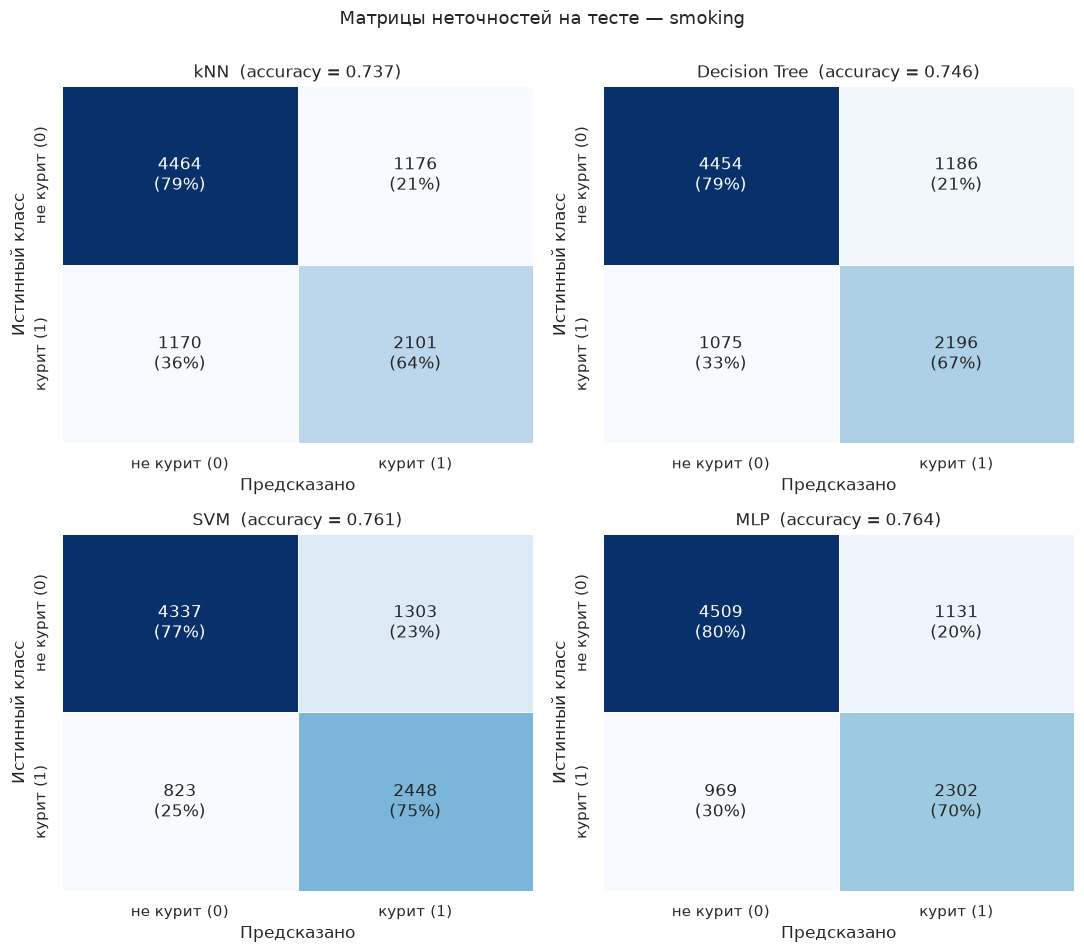

In [21]:
plot_confusion_matrices("smoking")

### 4.2. Классификационные отчёты

In [22]:
print_reports("smoking")

kNN — smoking
              precision    recall  f1-score   support

не курит (0)      0.792     0.791     0.792      5640
   курит (1)      0.641     0.642     0.642      3271

    accuracy                          0.737      8911
   macro avg      0.717     0.717     0.717      8911
weighted avg      0.737     0.737     0.737      8911

Decision Tree — smoking
              precision    recall  f1-score   support

не курит (0)      0.806     0.790     0.798      5640
   курит (1)      0.649     0.671     0.660      3271

    accuracy                          0.746      8911
   macro avg      0.727     0.731     0.729      8911
weighted avg      0.748     0.746     0.747      8911

SVM — smoking
              precision    recall  f1-score   support

не курит (0)      0.841     0.769     0.803      5640
   курит (1)      0.653     0.748     0.697      3271

    accuracy                          0.761      8911
   macro avg      0.747     0.759     0.750      8911
weighted avg      0.77

### 4.3. ROC-кривые

Показывают, как меняется баланс между долей найденных курильщиков (TPR) и долей ложных тревог (FPR) при изменении порога классификации.

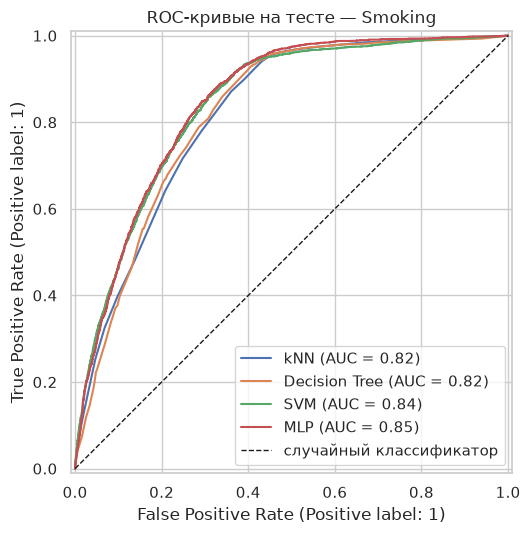

In [23]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name, model in MODELS["smoking"].items():
    RocCurveDisplay.from_estimator(model, DATA["smoking"]["X_test"], DATA["smoking"]["y_test"],
                                   name=MODEL_NAMES[name], ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="случайный классификатор")
ax.set_title("ROC-кривые на тесте — Smoking")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 4.4. Сравнительная таблица

Зелёным выделен лучший результат в каждом столбце. `CV F1 (macro)` — результат кросс-валидации из части 2, `F1 macro до подбора` — тот же показатель на тесте у модели с параметрами по умолчанию.

In [24]:
cmp_smoking = comparison_table("smoking")
cmp_smoking.to_csv(RESULTS_DIR / "comparison_smoking.csv")
style_table(cmp_smoking)

,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),ROC-AUC,CV F1 (macro),F1 macro до подбора
kNN,0.7367,0.7167,0.7169,0.7168,0.7368,0.8204,0.7125,0.6801
Decision Tree,0.7463,0.7274,0.7305,0.7289,0.7471,0.8213,0.7222,0.6631
SVM,0.7614,0.7466,0.7587,0.7502,0.7643,0.8411,0.7330,0.7511
MLP,0.7643,0.7468,0.7516,0.7489,0.7655,0.8469,0.7427,0.7486


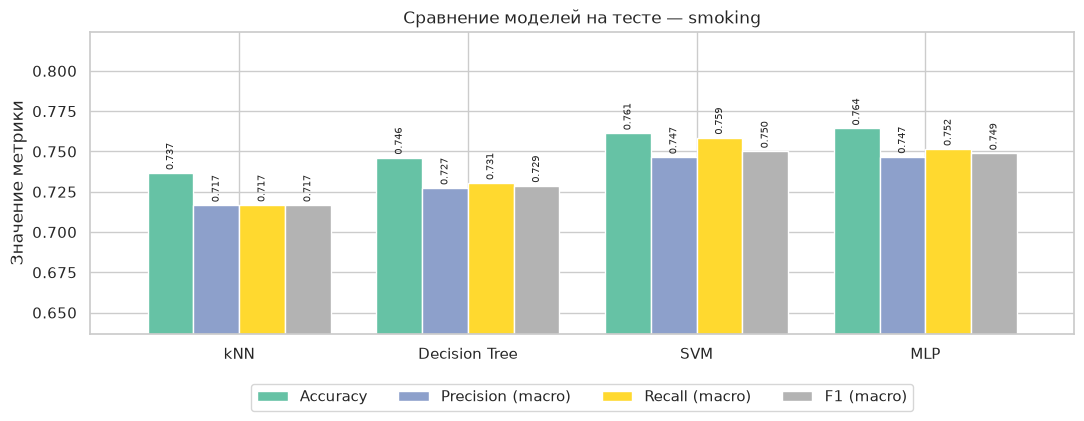

In [25]:
plot_comparison(cmp_smoking, "smoking")

## 5. Датасет Drug200

Для теста выбрано всего 40 объектов, поэтому одна ошибка очень сильно меняет процент accuracy. 

### 5.1. Матрицы неточностей

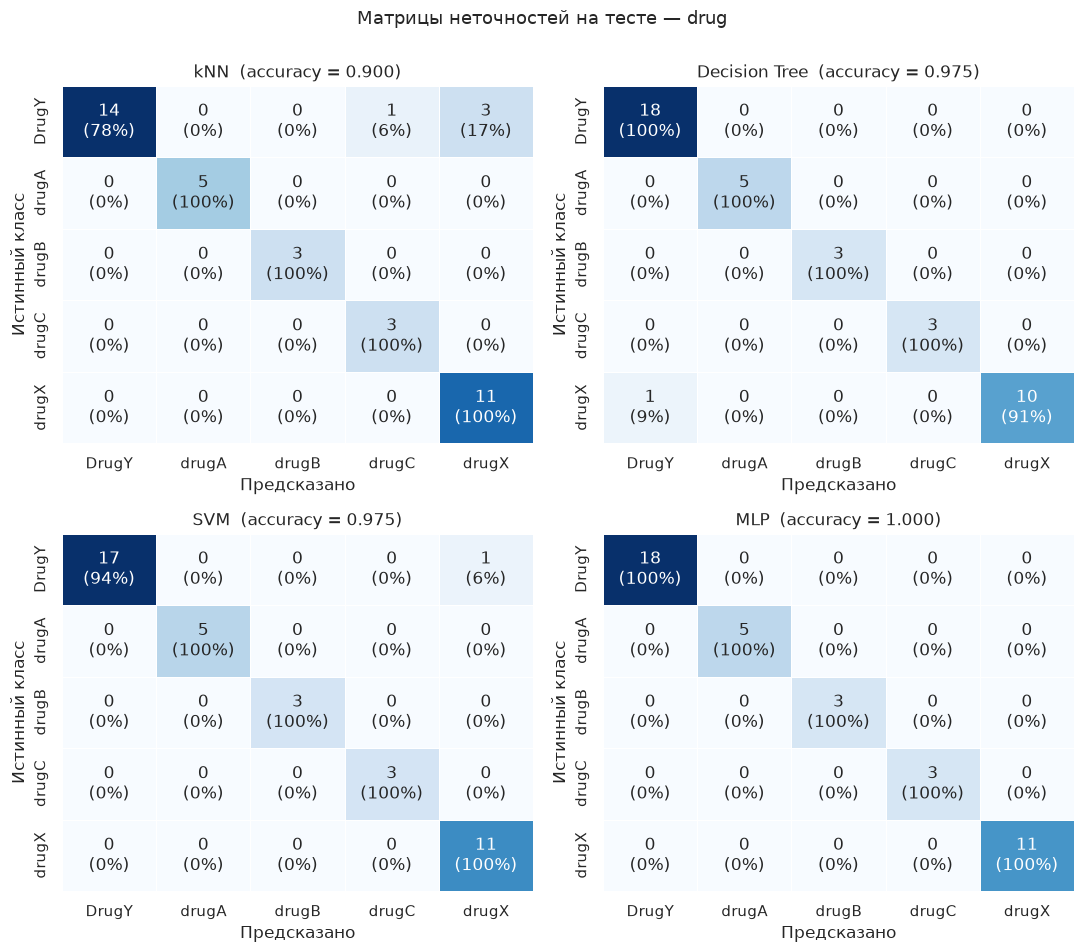

In [26]:
plot_confusion_matrices("drug")

### 5.2. Классификационные отчёты

In [27]:
print_reports("drug")

kNN — drug
              precision    recall  f1-score   support

       DrugY      1.000     0.778     0.875        18
       drugA      1.000     1.000     1.000         5
       drugB      1.000     1.000     1.000         3
       drugC      0.750     1.000     0.857         3
       drugX      0.786     1.000     0.880        11

    accuracy                          0.900        40
   macro avg      0.907     0.956     0.922        40
weighted avg      0.922     0.900     0.900        40

Decision Tree — drug
              precision    recall  f1-score   support

       DrugY      0.947     1.000     0.973        18
       drugA      1.000     1.000     1.000         5
       drugB      1.000     1.000     1.000         3
       drugC      1.000     1.000     1.000         3
       drugX      1.000     0.909     0.952        11

    accuracy                          0.975        40
   macro avg      0.989     0.982     0.985        40
weighted avg      0.976     0.975     0.975  

### 5.3. Сравнительная таблица

In [28]:
cmp_drug = comparison_table("drug")
cmp_drug.to_csv(RESULTS_DIR / "comparison_drug.csv")
style_table(cmp_drug.drop(columns=["ROC-AUC"], errors="ignore"))

,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),CV F1 (macro),F1 macro до подбора
kNN,0.9000,0.9071,0.9556,0.9224,0.9000,0.9111,0.8027
Decision Tree,0.9750,0.9895,0.9818,0.9851,0.9747,0.9810,0.9851
SVM,0.9750,0.9833,0.9889,0.9856,0.9752,0.9600,1.0000
MLP,1.0000,1.0000,1.0000,1.0000,1.0000,0.9592,1.0000


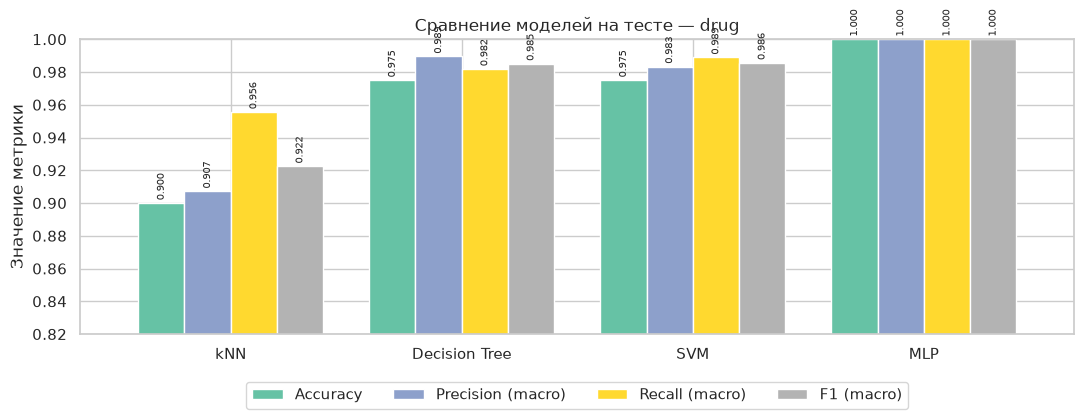

In [29]:
plot_comparison(cmp_drug, "drug")

### 5.4. F1-score по классам

Показывает, на каких препаратах модели ошибаются чаще всего.

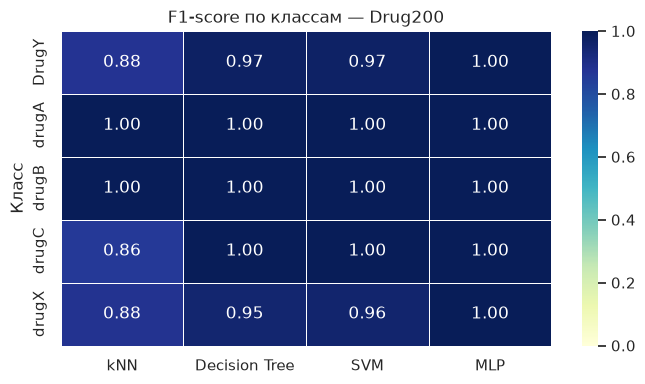

In [30]:
labels = TARGET_NAMES["drug"]
per_class = pd.DataFrame({
    MODEL_NAMES[name]: f1_score(DATA["drug"]["y_test"], model.predict(DATA["drug"]["X_test"]),
                                labels=labels, average=None, zero_division=0)
    for name, model in MODELS["drug"].items()
}, index=labels)
per_class.index.name = "Класс"

fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(per_class, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1, ax=ax, linewidths=0.5)
ax.set_title("F1-score по классам — Drug200")
plt.tight_layout()
plt.show()